In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Environment is ready! :)")

Pandas version: 3.1.1
NumPy version: 2.5.5
Environment is ready! :)


In [11]:
PROJECT_ROOT = Path.cwd().parent
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

source_files = sorted(RAW_DATA_DIR.glob("*.csv"))

print("Raw-data folder:", RAW_DATA_DIR)
print("Number of CSV files:", len(source_files))

for file in source_files:
    print(file.name)

Raw-data folder: C:\Users\ashirvad.s.singh\Desktop\Capstone\data\raw
Number of CSV files: 6
chicago_city_community.csv
chicago_crime_dataset.csv
chicago_district_ps_info.csv
chicago_police_beat_info.csv
chicago_ward_offices.csv
iucr_codes.csv.csv


In [12]:
crime_df = pd.read_csv(
    RAW_DATA_DIR / "chicago_crime_dataset.csv",
    low_memory=False,
    on_bad_lines="warn"
)

community_df = pd.read_csv(
    RAW_DATA_DIR / "chicago_city_community.csv",
    low_memory=False,
    on_bad_lines="warn"
)

district_df = pd.read_csv(
    RAW_DATA_DIR / "chicago_district_ps_info.csv",
    low_memory=False,
    on_bad_lines="warn"
)

beat_df = pd.read_csv(
    RAW_DATA_DIR / "chicago_police_beat_info.csv",
    low_memory=False,
    on_bad_lines="warn"
)

ward_df = pd.read_csv(
    RAW_DATA_DIR / "chicago_ward_offices.csv",
    low_memory=False,
    on_bad_lines="warn"
)

iucr_df = pd.read_csv(
    RAW_DATA_DIR / "iucr_codes.csv.csv",
    low_memory=False,
    on_bad_lines="warn"
)

print("All six CSV files loaded successfully.")

C:\Users\ashirvad.s.singh\AppData\Local\Temp\ipykernel_27360\3455002262.py:1: ParserWarning: Skipping line 498: expected 20 fields, saw 21

  crime_df = pd.read_csv(


All six CSV files loaded successfully.


In [19]:
def inspect_data(df, file_name):
    print("=" * 100)
    print("FILE NAME:", file_name)
    print("=" * 100)

    # Number of rows and columns
    print("\n1. SHAPE")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])

    # First five records
    print("\n2. FIRST 10 ROWS")
    display(df.head(10))

    # Column names
    print("\n3. COLUMN NAMES")
    for number, column in enumerate(df.columns, start=1):
        print(number, repr(column))

    # Data types
    print("\n4. DATA TYPES")
    display(
        df.dtypes
        .astype(str)
        .reset_index(name="data_type")
        .rename(columns={"index": "column_name"})
    )

    # Missing values
    print("\n5. MISSING VALUES")

    missing_report = pd.DataFrame({
        "column_name": df.columns,
        "missing_count": df.isna().sum().values,
        "missing_percentage": (
            df.isna().mean().values * 100
        ).round(2)
    })

    missing_report = missing_report.sort_values(
        by="missing_percentage",
        ascending=False
    ).reset_index(drop=True)

    display(missing_report)

    # Exact duplicate rows
    print("\n6. DUPLICATE ROWS")

    duplicate_count = df.duplicated().sum()

    duplicate_percentage = (
        duplicate_count / len(df) * 100
        if len(df) > 0
        else 0
    )

    print("Duplicate rows:", duplicate_count)
    print(
        "Duplicate percentage:",
        round(duplicate_percentage, 2),
        "%"
    )

    # Unique values per column
    print("\n7. UNIQUE VALUES PER COLUMN")

    unique_report = pd.DataFrame({
        "column_name": df.columns,
        "unique_count": [
            df[column].nunique(dropna=True)
            for column in df.columns
        ]
    })

    display(unique_report)

    # Memory consumption
    print("\n8. MEMORY USAGE")

    memory_mb = (
        df.memory_usage(deep=True).sum()
        / (1024 ** 2)
    )

    print("Approximate memory:", round(memory_mb, 2), "MB")

    # Return the reports for later use
    return missing_report, unique_report

In [20]:
crime_missing, crime_unique = inspect_data(
    crime_df,
    "chicago_crime_dataset.csv"
)

FILE NAME: chicago_crime_dataset.csv

1. SHAPE
Rows: 496
Columns: 20

2. FIRST 10 ROWS


,id,case_number,date,block,iucr_code,location_desc,arrest,domestic,beat_num,district_code,ward_no,community_code,fbi_code,x_coordinate,y_coordinate,year,date_of_update,latitude,longitude,location
0,10508693,HZ250496,5/3/2016,013XX S SAWYER AVE,486,APARTMENT,True,True,1022,10,24,29,08B,1154907.0,1893681.0,2016,5/10/2016,41.864073,-87.706819,"(41.864073157, -87.706818608)"
1,10508695,HZ250409,5/3/2016,061XX S DREXEL AVE,486,RESIDENCE,False,True,313,3,20,42,08B,1183066.0,1864330.0,2016,5/10/2016,41.782922,-87.604363,"(41.782921527, -87.60436317)"
2,10508697,HZ250503,5/3/2016,053XX W CHICAGO AVE,470,STREET,False,False,1524,15,37,25,24,1140789.0,1904819.0,2016,5/10/2016,41.894908,-87.758372,"(41.894908283, -87.758371958)"
3,10508698,HZ250424,5/3/2016,049XX W FULTON ST,460,SIDEWALK,False,False,1532,15,28,25,08B,1143223.0,1901475.0,2016,5/10/2016,41.885687,-87.749516,"(41.885686845, -87.749515983)"
4,10508699,HZ250455,5/3/2016,003XX N LOTUS AVE,820,RESIDENCE,False,True,1523,15,28,25,6,1139890.0,1901675.0,2016,5/10/2016,41.886297,-87.761751,"(41.886297242, -87.761750709)"
5,10508702,HZ250447,5/3/2016,082XX S MARYLAND AVE,041A,STREET,False,False,631,6,8,44,04B,1183336.0,1850642.0,2016,5/10/2016,41.745354,-87.603799,"(41.745354023, -87.603798903)"
6,10508703,HZ250489,5/3/2016,027XX S STATE ST,460,CHA HALLWAY/STAIRWELL/ELEVATOR,False,False,133,1,3,35,08B,1176730.0,1886544.0,2016,5/10/2016,41.844024,-87.626923,"(41.844023772, -87.626923253)"
7,10508704,HZ250514,5/3/2016,002XX E 46TH ST,460,RESIDENCE PORCH/HALLWAY,False,False,215,2,3,38,08B,1178514.0,1874573.0,2016,5/10/2016,41.811134,-87.620741,"(41.811133958, -87.62074077)"
8,10508709,HZ250523,5/3/2016,014XX W DEVON AVE,460,SIDEWALK,False,False,2432,24,40,1,08B,1165696.0,1942616.0,2016,5/10/2016,41.998131,-87.665814,"(41.99813061, -87.665814038)"
9,10508982,HZ250667,5/3/2016,069XX S ASHLAND AVE,486,STREET,False,True,735,7,17,67,08B,1166876.0,1858796.0,2016,5/10/2016,41.768097,-87.663879,"(41.768096835, -87.663878589)"



3. COLUMN NAMES
1 'id'
2 'case_number'
3 'date'
4 'block'
5 'iucr_code'
6 'location_desc'
7 'arrest'
8 'domestic'
9 'beat_num'
10 'district_code'
11 'ward_no'
12 'community_code'
13 'fbi_code'
14 'x_coordinate'
15 'y_coordinate'
16 'year'
17 'date_of_update'
18 'latitude'
19 'longitude'
20 'location'

4. DATA TYPES


,column_name,data_type
0,id,int64
1,case_number,str
2,date,str
3,block,str
4,iucr_code,str
5,location_desc,str
6,arrest,bool
7,domestic,bool
8,beat_num,int64
9,district_code,int64



5. MISSING VALUES


,column_name,missing_count,missing_percentage
0,location,29,5.85
1,y_coordinate,29,5.85
2,longitude,29,5.85
3,latitude,29,5.85
4,x_coordinate,29,5.85
5,location_desc,4,0.81
6,case_number,0,0.00
7,id,0,0.00
8,block,0,0.00
9,date,0,0.00



6. DUPLICATE ROWS
Duplicate rows: 0
Duplicate percentage: 0.0 %

7. UNIQUE VALUES PER COLUMN


,column_name,unique_count
0,id,496
1,case_number,496
2,date,46
3,block,474
4,iucr_code,97
5,location_desc,47
6,arrest,2
7,domestic,2
8,beat_num,209
9,district_code,22



8. MEMORY USAGE
Approximate memory: 0.11 MB


In [21]:
community_missing, community_unique = inspect_data(
    community_df,
    "chicago_city_community.csv"
)

FILE NAME: chicago_city_community.csv

1. SHAPE
Rows: 77
Columns: 7

2. FIRST 10 ROWS


,community_code,community_name,population,area_sqmile,area_sqkm,density_per_sqmi,density_per_sqkm
0,1,Rogers Park,"54,388",1.84,4.77,"29,558.70","11,412.61"
1,2,West Ridge,"78,227",3.53,9.14,"22,160.62","8,556.22"
2,3,Uptown,"57,331",2.32,6.01,"24,711.64","9,541.16"
3,4,Lincoln Square,"41,673",2.56,6.63,"16,278.52","6,285.13"
4,5,North Center,"35,408",2.05,5.31,"17,272.20","6,668.79"
5,6,Lake View,"101,163",3.12,8.08,"32,424.04","12,518.92"
6,7,Lincoln Park,"67,831",3.16,8.18,"21,465.51","8,287.83"
7,8,Near North Side,"104,712",2.74,7.10,"38,216.06","14,755.22"
8,9,Edison Park,"11,203",1.13,2.93,"9,914.16","3,827.86"
9,10,Norwood Park,"38,895",4.37,11.32,"8,900.46","3,436.47"



3. COLUMN NAMES
1 'community_code'
2 'community_name'
3 'population'
4 'area_sqmile'
5 'area_sqkm'
6 'density_per_sqmi'
7 'density_per_sqkm'

4. DATA TYPES


,column_name,data_type
0,community_code,int64
1,community_name,str
2,population,str
3,area_sqmile,float64
4,area_sqkm,float64
5,density_per_sqmi,str
6,density_per_sqkm,str



5. MISSING VALUES


,column_name,missing_count,missing_percentage
0,community_code,0,0.0
1,community_name,0,0.0
2,population,0,0.0
3,area_sqmile,0,0.0
4,area_sqkm,0,0.0
5,density_per_sqmi,0,0.0
6,density_per_sqkm,0,0.0



6. DUPLICATE ROWS
Duplicate rows: 0
Duplicate percentage: 0.0 %

7. UNIQUE VALUES PER COLUMN


,column_name,unique_count
0,community_code,77
1,community_name,77
2,population,77
3,area_sqmile,69
4,area_sqkm,69
5,density_per_sqmi,77
6,density_per_sqkm,77



8. MEMORY USAGE
Approximate memory: 0.01 MB


In [22]:
district_missing, district_unique = inspect_data(
    district_df,
    "chicago_district_ps_info.csv"
)

FILE NAME: chicago_district_ps_info.csv

1. SHAPE
Rows: 22
Columns: 15

2. FIRST 10 ROWS


,DISTRICT_CODE,DISTRICT_NAME,ADDRESS,CITY,STATE,ZIP,WEBSITE,PHONE,FAX,TTY,X_COORDINATE,Y_COORDINATE,LATITUDE,LONGITUDE,LOCATION
0,1,Central,1718 S State St,Chicago,IL,60616,http://home.chicagopolice.org/community/distri...,312-745-4290,312-745-3694,312-745-3693,1176569.052,1891771.704,41.858373,-87.627356,"(41.8583725929, -87.627356171)"
1,2,Wentworth,5101 S Wentworth Ave,Chicago,IL,60609,http://home.chicagopolice.org/community/distri...,312-747-8366,312-747-5396,312-747-6656,1175864.837,1871153.753,41.801811,-87.630560,"(41.8018110912, -87.6305601801)"
2,3,Grand Crossing,7040 S Cottage Grove Ave,Chicago,IL,60637,http://home.chicagopolice.org/community/distri...,312-747-8201,312-747-5479,312-747-9168,1182739.183,1858317.732,41.766431,-87.605748,"(41.7664308925, -87.6057478606)"
3,4,South Chicago,2255 E 103rd St,Chicago,IL,60617,http://home.chicagopolice.org/community/distri...,312-747-7581,312-747-5276,312-747-9169,1193131.299,1837090.265,41.707933,-87.568349,"(41.7079332906, -87.5683491228)"
4,5,Calumet,727 E 111th St,Chicago,IL,60628,http://home.chicagopolice.org/community/distri...,312-747-8210,312-747-5935,312-747-9170,1183305.427,1831462.313,41.692723,-87.604506,"(41.6927233639, -87.6045058667)"
5,6,Gresham,7808 S Halsted St,Chicago,IL,60620,http://home.chicagopolice.org/community/distri...,312-745-3617,312-745-3649,312-745-3639,1172283.013,1853022.646,41.752137,-87.644229,"(41.7521368378, -87.6442289066)"
6,7,Englewood,1438 W 63rd St,Chicago,IL,60636,http://home.chicagopolice.org/community/distri...,312-747-8223,312-747-6558,312-747-6652,1167659.235,1863005.522,41.779632,-87.660887,"(41.7796315359, -87.6608870173)"
7,8,Chicago Lawn,3420 W 63rd St,Chicago,IL,60629,http://home.chicagopolice.org/community/distri...,312-747-8730,312-747-8545,312-747-8116,1154575.242,1862672.049,41.778987,-87.708864,"(41.778987189, -87.7088638153)"
8,9,Deering,3120 S Halsted St,Chicago,IL,60608,http://home.chicagopolice.org/community/distri...,312-747-8227,312-747-5329,312-747-9172,1171440.240,1884085.224,41.837394,-87.646408,"(41.8373944311, -87.6464077068)"
9,10,Ogden,3315 W Ogden Ave,Chicago,IL,60623,http://home.chicagopolice.org/community/distri...,312-747-7511,312-747-7429,312-747-7471,1154500.753,1890985.501,41.856685,-87.708382,"(41.8566845327, -87.708381958)"



3. COLUMN NAMES
1 'DISTRICT_CODE'
2 'DISTRICT_NAME'
3 'ADDRESS'
4 'CITY'
5 'STATE'
6 'ZIP'
7 'WEBSITE'
8 'PHONE'
9 'FAX'
10 'TTY'
11 'X_COORDINATE'
12 'Y_COORDINATE'
13 'LATITUDE'
14 'LONGITUDE'
15 'LOCATION'

4. DATA TYPES


,column_name,data_type
0,DISTRICT_CODE,int64
1,DISTRICT_NAME,str
2,ADDRESS,str
3,CITY,str
4,STATE,str
5,ZIP,int64
6,WEBSITE,str
7,PHONE,str
8,FAX,str
9,TTY,str



5. MISSING VALUES


,column_name,missing_count,missing_percentage
0,DISTRICT_CODE,0,0.0
1,DISTRICT_NAME,0,0.0
2,ADDRESS,0,0.0
3,CITY,0,0.0
4,STATE,0,0.0
5,ZIP,0,0.0
6,WEBSITE,0,0.0
7,PHONE,0,0.0
8,FAX,0,0.0
9,TTY,0,0.0



6. DUPLICATE ROWS
Duplicate rows: 0
Duplicate percentage: 0.0 %

7. UNIQUE VALUES PER COLUMN


,column_name,unique_count
0,DISTRICT_CODE,22
1,DISTRICT_NAME,22
2,ADDRESS,22
3,CITY,1
4,STATE,1
5,ZIP,20
6,WEBSITE,22
7,PHONE,22
8,FAX,22
9,TTY,22



8. MEMORY USAGE
Approximate memory: 0.01 MB


In [23]:
beat_missing, beat_unique = inspect_data(
    beat_df,
    "chicago_police_beat_info.csv"
)

FILE NAME: chicago_police_beat_info.csv

1. SHAPE
Rows: 277
Columns: 4

2. FIRST 10 ROWS


,DISTRICT,SECTOR,BEAT,BEAT_NUM
0,17,1,1,1713
1,31,0,0,3100
2,16,5,5,1651
3,19,1,1,1914
4,19,1,1,1915
5,19,1,1,1913
6,7,3,3,735
7,19,1,1,1912
8,17,2,2,1723
9,19,1,1,1911



3. COLUMN NAMES
1 'DISTRICT'
2 'SECTOR'
3 'BEAT'
4 'BEAT_NUM'

4. DATA TYPES


,column_name,data_type
0,DISTRICT,int64
1,SECTOR,int64
2,BEAT,int64
3,BEAT_NUM,int64



5. MISSING VALUES


,column_name,missing_count,missing_percentage
0,DISTRICT,0,0.0
1,SECTOR,0,0.0
2,BEAT,0,0.0
3,BEAT_NUM,0,0.0



6. DUPLICATE ROWS
Duplicate rows: 2
Duplicate percentage: 0.72 %

7. UNIQUE VALUES PER COLUMN


,column_name,unique_count
0,DISTRICT,23
1,SECTOR,5
2,BEAT,5
3,BEAT_NUM,275



8. MEMORY USAGE
Approximate memory: 0.01 MB


In [24]:
ward_missing, ward_unique = inspect_data(
    ward_df,
    "chicago_ward_offices.csv"
)

FILE NAME: chicago_ward_offices.csv

1. SHAPE
Rows: 58
Columns: 20

2. FIRST 10 ROWS


,ward,alderman,address,city,state,zipcode,ward_phone,ward_fax,email,website,location_zip,location_city,location,location_address,location_state,city_hall_address,city_hall_city,city_hall_state,city_hall_zipcode,city_hall_phone
0,42,"Reilly, Brendan",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"121 North LaSalle Street, Room 200,Office 6",Chicago,IL,60602.0,(312) 744-3062
1,34,"Austin, Carrie M.",507 West 111th Street,Chicago,IL,60628.0,(773) 928-6961,(773) 928-8562,Ward34@cityofchicago.org,http://www.34thward.org,NaN,NaN,POINT (-87.635452 41.692436),NaN,NaN,"121 North LaSalle Street, Room 200, Office 21",Chicago,IL,60602.0,(312) 744-6820 / 6829
2,46,"Cappleman, James",4544 North Broadway,Chicago,IL,60640.0,(773) 878-4646,(773) 878-4920,Ward46@cityofchicago.org,http://www.James46.org/,NaN,NaN,POINT (-87.656942 41.964594),NaN,NaN,"121 North LaSalle Street, Room 200, Office 10",Chicago,IL,60602.0,(312) 744-6831 / 5694
3,3,"Dowell, Pat",5046 South State Street,Chicago,IL,60609.0,(773) 373-9273,(773) 373-6852,Ward03@cityofchicago.org,http://www.ward03chicago.com,NaN,NaN,POINT (-87.625955 41.802977),NaN,NaN,"121 North LaSalle Street, Room 200, Office 3",Chicago,IL,60602.0,(312) 744-8734 / 6712
4,38,"Sposato, Nicholas",3821 North Harlem Avenue,Chicago,IL,60634.0,(773) 283-3838,(773) 283-3235,Ward38@cityofchicago.org,http://aldermansposato.com/,NaN,NaN,POINT (-87.807131 41.949577),NaN,NaN,"121 North LaSalle Street, Room 200, Office 2",Chicago,IL,60602.0,(312) 744-6857
5,37,"Mitts, Emma",4924 West Chicago Avenue,Chicago,IL,60651.0,(773) 379-0960,(773) 773-0966,Ward37@cityofchicago.org,https://www.cityofchicago.org/city/en/about/wa...,NaN,NaN,POINT (-87.749236 41.895006),NaN,NaN,"121 North LaSalle Street, Room 300, Office 45",Chicago,IL,60602.0,(312) 744-3180 / 1589
6,6,"Sawyer, Roderick T.",700 East 79th Street,Chicago,IL,60619.0,(773) 635-0006,(773) 891-5679,Ward06@cityofchicago.org,http://www.6ward.com,NaN,NaN,POINT (-87.607315 41.75124),NaN,NaN,"121 North LaSalle Street, Room 300",Chicago,IL,60602.0,(312) 744-6868
7,17,"Moore, David H.",1344 West 79th Street,Chicago,IL,60636.0,(773) 783-3672,(773) 783-3878,David.Moore@cityofchicago.org,http://www.David.Moore@cityofchicago.org,NaN,NaN,POINT (-87.657221 41.75044),NaN,NaN,"121 North LaSalle Street, Room 300, Office 37",Chicago,IL,60602.0,(312) 744-3435
8,5,"Hairston, Leslie A.",2325 East 71st Street,Chicago,IL,60649.0,(773) 324-5555,(773) 324-1585,Ward05@cityofchicago.org,http://leslieahairston.com/,NaN,NaN,POINT (-87.567641 41.766147),NaN,NaN,"121 North LaSalle Street, Room 300, Office 26",Chicago,IL,60602.0,(312) 744-6832 / 3195
9,15,"Lopez, Raymond A.",6412 South Ashland Avenue,Chicago,IL,60636.0,(773) 823-1539,(773) 424-8720,Ward15@cityofchicago.org,http://www.the15thward.org,NaN,NaN,POINT (-87.664246 41.777028),NaN,NaN,"121 North LaSalle Street, Room 300, Office 42",Chicago,IL,60602.0,(312) 744-4321



3. COLUMN NAMES
1 'ward'
2 'alderman'
3 'address'
4 'city'
5 'state'
6 'zipcode'
7 'ward_phone'
8 'ward_fax'
9 'email'
10 'website'
11 'location_zip'
12 'location_city'
13 'location'
14 'location_address'
15 'location_state'
16 'city_hall_address'
17 'city_hall_city'
18 'city_hall_state'
19 'city_hall_zipcode'
20 'city_hall_phone'

4. DATA TYPES


,column_name,data_type
0,ward,int64
1,alderman,str
2,address,str
3,city,str
4,state,str
5,zipcode,float64
6,ward_phone,str
7,ward_fax,str
8,email,str
9,website,str



5. MISSING VALUES


,column_name,missing_count,missing_percentage
0,location_address,58,100.00
1,location_state,58,100.00
2,location_city,58,100.00
3,location_zip,58,100.00
4,ward_fax,16,27.59
5,website,12,20.69
6,city_hall_phone,3,5.17
7,email,2,3.45
8,zipcode,1,1.72
9,state,1,1.72



6. DUPLICATE ROWS
Duplicate rows: 0
Duplicate percentage: 0.0 %

7. UNIQUE VALUES PER COLUMN


,column_name,unique_count
0,ward,50
1,alderman,54
2,address,55
3,city,1
4,state,1
5,zipcode,34
6,ward_phone,52
7,ward_fax,40
8,email,52
9,website,43



8. MEMORY USAGE
Approximate memory: 0.02 MB


In [25]:
crime_clean = crime_df.copy()
community_clean = community_df.copy()
district_clean = district_df.copy()
beat_clean = beat_df.copy()
ward_clean = ward_df.copy()
iucr_clean = iucr_df.copy()

print("Working copies created.")

Working copies created.


In [29]:
crime_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 496 entries, 0 to 495
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              496 non-null    int64  
 1   case_number     496 non-null    str    
 2   date            496 non-null    str    
 3   block           496 non-null    str    
 4   iucr_code       496 non-null    str    
 5   location_desc   492 non-null    str    
 6   arrest          496 non-null    bool   
 7   domestic        496 non-null    bool   
 8   beat_num        496 non-null    int64  
 9   district_code   496 non-null    int64  
 10  ward_no         496 non-null    int64  
 11  community_code  496 non-null    int64  
 12  fbi_code        496 non-null    str    
 13  x_coordinate    467 non-null    float64
 14  y_coordinate    467 non-null    float64
 15  year            496 non-null    int64  
 16  date_of_update  496 non-null    str    
 17  latitude        467 non-null    float64
 18  l

In [ ]:
#both dates & date_of_update are in str but before we make it to datetime we need to check if all dates are in same format

In [33]:
print("Unique crime-date strings:", crime_clean["date"].nunique())
print("Unique update-date strings:", crime_clean["date_of_update"].nunique())

display(
    crime_clean["date"]
    .value_counts()
)

display(
    crime_clean["date_of_update"]
    .value_counts()
)

Unique crime-date strings: 46
Unique update-date strings: 3


date
5/4/2016      296
5/3/2016      145
4/1/2016        4
1/1/2015        2
1/1/2016        2
4/4/2016        2
4/11/2016       2
3/15/2016       2
3/14/2016       2
1/1/2012        2
4/25/2016       2
3/21/2016       1
11/24/2015      1
4/5/2016        1
1/15/2016       1
4/12/2016       1
5/1/2016        1
4/2/2016        1
4/9/2016        1
2/28/2016       1
3/9/2016        1
3/1/2016        1
5/19/2015       1
1/13/2016       1
1/19/2016       1
1/25/2016       1
2/5/2016        1
2/18/2016       1
3/2/2016        1
3/5/2016        1
3/18/2016       1
2/27/2016       1
3/22/2016       1
4/17/2016       1
4/18/2016       1
2/2/2016        1
4/22/2016       1
4/24/2016       1
4/15/2016       1
4/26/2016       1
4/27/2016       1
4/28/2016       1
5/2/2016        1
3/31/2016       1
11/1/2014       1
5/1/2013        1
Name: count, dtype: int64

date_of_update
5/11/2016    331
5/10/2016    163
5/23/2016      2
Name: count, dtype: int64

In [ ]:
#all seems in month/date/year

In [34]:
crime_clean["date"] = pd.to_datetime(
    crime_clean["date"],
    format="%m/%d/%Y",
    errors="coerce"
)

crime_clean["date_of_update"] = pd.to_datetime(
    crime_clean["date_of_update"],
    format="%m/%d/%Y",
    errors="coerce"
)

In [37]:
crime_clean[["date","date_of_update"]].info()
#converted

<class 'pandas.DataFrame'>
RangeIndex: 496 entries, 0 to 495
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   date            496 non-null    datetime64[us]
 1   date_of_update  496 non-null    datetime64[us]
dtypes: datetime64[us](2)
memory usage: 7.9 KB


In [39]:
#crime dataset already has a year column 
crime_clean["year"].head()

0    2016
1    2016
2    2016
3    2016
4    2016
Name: year, dtype: int64

In [41]:
crime_clean["Year"] = crime_clean["date"].dt.year
crime_clean["Month"] = crime_clean["date"].dt.month
crime_clean["DayOfWeek"] = crime_clean["date"].dt.day_name()


In [42]:
crime_clean.columns

Index(['id', 'case_number', 'date', 'block', 'iucr_code', 'location_desc',
       'arrest', 'domestic', 'beat_num', 'district_code', 'ward_no',
       'community_code', 'fbi_code', 'x_coordinate', 'y_coordinate', 'year',
       'date_of_update', 'latitude', 'longitude', 'location', 'month',
       'day_of_week', 'Year', 'Month', 'DayOfWeek'],
      dtype='str')

In [47]:
#fixing missing values
crime_missing[crime_missing["missing_count"] > 0]

,column_name,missing_count,missing_percentage
0,location,29,5.85
1,y_coordinate,29,5.85
2,longitude,29,5.85
3,latitude,29,5.85
4,x_coordinate,29,5.85
5,location_desc,4,0.81


In [ ]:
#above have missing values
#location_desc is categorical text, filling it with a mean or median would make no sense. Hence we will make it UNKNOWN

In [48]:
crime_clean["location_desc"] = (
    crime_clean["location_desc"]
    .fillna("UNKNOWN")
)

In [52]:
crime_clean[crime_clean["location"].isna()].sample(1)

,id,case_number,date,block,iucr_code,location_desc,arrest,domestic,beat_num,district_code,...,year,date_of_update,latitude,longitude,location,month,day_of_week,Year,Month,DayOfWeek
175,10516273,HZ258443,2016-03-14,109XX S DOTY AVE E,1150,SMALL RETAIL STORE,False,False,513,5,...,2016,2016-05-10,NaN,NaN,NaN,3,Monday,2016,3,Monday


In [ ]:
#we cannot invent a location and the filed are numbers so NaN is good enough

In [58]:
#crime str columns

for col in crime_clean.columns:
    if crime_clean[col].dtype == 'str':
        print(col)

case_number
block
iucr_code
location_desc
fbi_code
location
day_of_week
DayOfWeek


In [59]:
#we got the dates , not needed
crime_categorical_columns = [
    "case_number",
    "block",
    "iucr_code",
    "location_desc",
    "fbi_code"
]

for col in crime_categorical_columns:
    crime_clean[col] = (
        crime_clean[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.upper()
    )


In [67]:
#drop missing > 50% 
crime_missing["column_name"]
crime_missing[crime_missing["missing_percentage"] > 50]["column_name"].count()

np.int64(0)

In [ ]:
#no missing columns having more than 50% in Chicago crime dataset

In [68]:
ward_columns_above_50 = ward_missing[
    ward_missing["missing_percentage"] > 50
]

display(ward_columns_above_50)

,column_name,missing_count,missing_percentage
0,location_address,58,100.0
1,location_state,58,100.0
2,location_city,58,100.0
3,location_zip,58,100.0


In [ ]:
#ward dataset has 4 columns with 100% missing data hence we will drop them all

In [69]:
ward_drop_columns = (
    ward_columns_above_50["column_name"]
    .tolist()
)

print(ward_drop_columns)

['location_address', 'location_state', 'location_city', 'location_zip']


In [70]:
ward_clean = ward_clean.drop(columns=ward_drop_columns)

In [71]:
ward_clean.shape

(58, 16)

In [72]:
ward_df.shape

(58, 20)

In [ ]:
#as you can see the 4 columns are dropped

In [ ]:
#when we introduced new Date features in the Crime dataset, we already had the year, month and day_of_week so we will drop them

In [76]:
print(crime_clean.shape)
#crime_clean.columns

(496, 26)


In [79]:
crime_clean = crime_clean.drop(columns=["year",'month',"day_of_week"])
crime_clean.shape
#done 

(496, 23)

In [ ]:
# we also found duplicates in police_beat_info

In [80]:
beat_duplicate_rows = beat_clean[
    beat_clean.duplicated(keep=False)
].sort_values("BEAT_NUM")

display(beat_duplicate_rows)

,DISTRICT,SECTOR,BEAT,BEAT_NUM
1,31,0,0,3100
55,31,0,0,3100
263,31,0,0,3100


In [81]:
print(beat_clean.shape)
beat_clean = (
    beat_clean
    .drop_duplicates()
    .reset_index(drop=True)
)

beat_clean.shape

(277, 4)


(275, 4)

In [ ]:
#standardise, district and beat files use uppercase names while other files use lowercase

In [84]:
district_clean.columns = district_clean.columns.str.lower()

In [85]:
district_clean.columns

Index(['district_code', 'district_name', 'address', 'city', 'state', 'zip',
       'website', 'phone', 'fax', 'tty', 'x_coordinate', 'y_coordinate',
       'latitude', 'longitude', 'location'],
      dtype='str')

In [86]:
beat_clean.columns

Index(['DISTRICT', 'SECTOR', 'BEAT', 'BEAT_NUM'], dtype='str')

In [88]:
beat_clean.columns = beat_clean.columns.str.lower()
beat_clean.columns

Index(['district', 'sector', 'beat', 'beat_num'], dtype='str')

In [ ]:
#community contains ',' in numerical feilds 

In [90]:
community_clean.sample()

,community_code,community_name,population,area_sqmile,area_sqkm,density_per_sqmi,density_per_sqkm
65,66,Chicago Lawn,"53,460",3.53,9.14,"15,144.48","5,847.28"


In [91]:
comma_fields = ["population", "density_per_sqmi", "density_per_sqkm"]
for col in comma_fields:
    community_clean[col] = pd.to_numeric(
        community_clean[col].str.replace(",",""),
        errors="coerce"
    )
    

In [92]:
community_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   community_code    77 non-null     int64  
 1   community_name    77 non-null     str    
 2   population        77 non-null     int64  
 3   area_sqmile       77 non-null     float64
 4   area_sqkm         77 non-null     float64
 5   density_per_sqmi  77 non-null     float64
 6   density_per_sqkm  77 non-null     float64
dtypes: float64(4), int64(2), str(1)
memory usage: 5.2 KB


In [ ]:
#they became floats

In [98]:
#also i found zipcodes in ward to be float instead of int
ward_clean["zipcode"] = ward_clean["zipcode"].astype("int32",errors="ignore")

In [ ]:
#iucr standarization

In [115]:
iucr_clean.columns = (
    iucr_clean.columns
    .str.strip() #beacuse primary type has traing space
    .str.lower()
)
iucr_clean.columns

Index(['iucr', 'primary_type', 'description', 'index code'], dtype='str')

In [117]:
duplicate_iucr_count = (
    iucr_clean["iucr"]
    .duplicated()
    .sum()
)

print("Duplicate IUCR codes:", duplicate_iucr_count)

Duplicate IUCR codes: 0


In [ ]:
#time to merege

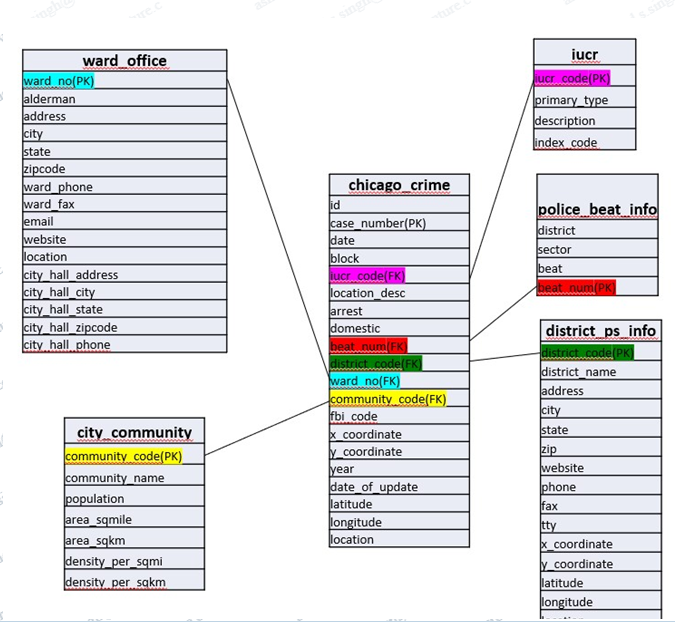

In [108]:
from IPython.display import Image, display

display(Image(filename="./relationship.png", width=500,height=400))


In [122]:
rows_before_merge = len(crime_clean)

crime_clean = crime_clean.merge(
    iucr_clean[
        [
            "iucr",
            "primary_type",
            "description",
            "index code"
        ]
    ],
    how="left",
    left_on="iucr_code",
    right_on="iucr",
    validate="many_to_one"
)

print("Rows before merge:", rows_before_merge)
print("Rows after merge:", len(crime_clean))

assert len(crime_clean) == rows_before_merge

print("Merge completed without changing the crime count.")

Rows before merge: 496
Rows after merge: 496
Merge completed without changing the crime count.


In [123]:
unique_crime_types = (
    crime_clean["primary_type"]
    .nunique()
)

print(
    "Number of unique crime types:",
    unique_crime_types
)

Number of unique crime types: 23


In [124]:
crime_type_counts = (
    crime_clean["primary_type"]
    .value_counts()
)

display(crime_type_counts)

primary_type
THEFT                               105
BATTERY                              85
CRIMINAL DAMAGE                      47
OTHER OFFENSE                        39
DECEPTIVE PRACTICE                   38
ASSAULT                              35
NARCOTICS                            32
ROBBERY                              30
CRIMINAL TRESPASS                    17
MOTOR VEHICLE THEFT                  16
BURGLARY                             14
WEAPONS VIOLATION                     8
PUBLIC PEACE VIOLATION                5
OFFENSE INVOLVING CHILDREN            5
CRIMINAL SEXUAL ASSAULT               4
SEX OFFENSE                           3
HOMICIDE                              3
PROSTITUTION                          3
KIDNAPPING                            2
INTERFERENCE WITH PUBLIC OFFICER      2
STALKING                              1
OBSCENITY                             1
GAMBLING                              1
Name: count, dtype: int64

In [125]:
crime_type_summary = (
    crime_clean["primary_type"]
    .value_counts()
    .rename_axis("primary_type")
    .reset_index(name="crime_count")
)

crime_type_summary["percentage"] = (
    crime_type_summary["crime_count"]
    / len(crime_clean)
    * 100
).round(2)

display(crime_type_summary)

,primary_type,crime_count,percentage
0,THEFT,105,21.17
1,BATTERY,85,17.14
2,CRIMINAL DAMAGE,47,9.48
3,OTHER OFFENSE,39,7.86
4,DECEPTIVE PRACTICE,38,7.66
5,ASSAULT,35,7.06
6,NARCOTICS,32,6.45
7,ROBBERY,30,6.05
8,CRIMINAL TRESPASS,17,3.43
9,MOTOR VEHICLE THEFT,16,3.23


In [ ]:
#for hourly predictions we dont have time in crimes, so i will be generating with the seed 42 

In [126]:

rng = np.random.default_rng(seed=42)

crime_clean["synthetic_hour"] = rng.integers(
    low=0,
    high=24,
    size=len(crime_clean)
)

In [128]:
def classify_time_period(hour):
    if 0 <= hour < 6:
        return "Late Night"
    elif 6 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 18:
        return "Afternoon"
    else:
        return "Evening"

crime_clean["synthetic_time_period"] = (
    crime_clean["synthetic_hour"]
    .apply(classify_time_period)
)

In [137]:
round(crime_clean["synthetic_hour"].value_counts()/crime_clean.shape[0]*100,2).sort_values(ascending=False)

synthetic_hour
18    5.65
10    5.65
3     5.65
2     5.44
11    5.44
13    5.04
7     5.04
15    4.84
19    4.84
23    4.44
17    4.44
6     4.44
16    4.03
22    4.03
0     4.03
4     3.83
8     3.63
20    3.02
12    3.02
21    3.02
5     2.82
1     2.62
14    2.62
9     2.42
Name: count, dtype: float64

In [ ]:
#most crimes at 6pm and least at 9am

In [138]:
round(crime_clean["synthetic_time_period"].value_counts()/crime_clean.shape[0]*100,2).sort_values(ascending=False)

synthetic_time_period
Morning       26.61
Evening       25.00
Late Night    24.40
Afternoon     23.99
Name: count, dtype: float64

In [ ]:
#in morning time period more crimes are done

# Use Case 2

In [144]:
print(crime_clean.shape)

crime_clean[
        [
            "date",
            "Year",
            "Month",
            "DayOfWeek",
            "primary_type",
            "arrest",
            "community_code"
        ]
    ].head()


(496, 29)


,date,Year,Month,DayOfWeek,primary_type,arrest,community_code
0,2016-05-03,2016,5,Tuesday,BATTERY,True,29
1,2016-05-03,2016,5,Tuesday,BATTERY,False,42
2,2016-05-03,2016,5,Tuesday,PUBLIC PEACE VIOLATION,False,25
3,2016-05-03,2016,5,Tuesday,BATTERY,False,25
4,2016-05-03,2016,5,Tuesday,THEFT,False,25


In [155]:
crimes_per_year = (
    crime_clean
    .groupby("Year")
    .size()
    .reset_index(name="crime_count")

)

crimes_per_year

,Year,crime_count
0,2012,2
1,2013,1
2,2014,1
3,2015,4
4,2016,488


In [ ]:
# most of the crimes in 2016

In [157]:
import matplotlib.pyplot as plt
import seaborn as sns

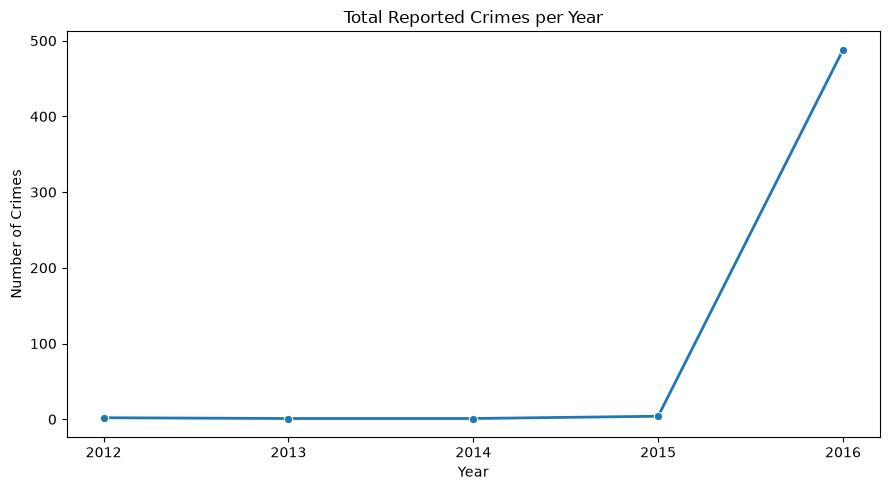

In [160]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=crimes_per_year,
    x="Year",
    y="crime_count",
    marker="o",
    linewidth=2
)

plt.title("Total Reported Crimes per Year")
plt.xlabel("Year")
plt.ylabel("Number of Crimes")
plt.xticks(crimes_per_year["Year"])

plt.tight_layout()
plt.show()

In [ ]:
#The jump in the crime rate is astranomical than 2015, but y? biased data?

In [161]:
crime_clean.groupby(["Year","Month"]).size()

Year  Month
2012  1          2
2013  5          1
2014  11         1
2015  1          2
      5          1
      11         1
2016  1          6
      2          5
      3         12
      4         22
      5        443
dtype: int64

In [ ]:
#we dont have all the data hence this is biased data towards 2016

In [164]:
crime_category_summary = (
    crime_clean["primary_type"]
    .value_counts()
    .reset_index(name="crime_count")
)

crime_category_summary["percentage"] = np.round(
    crime_category_summary["crime_count"]
    / len(crime_clean)
    * 100,
    2
)

crime_category_summary

,primary_type,crime_count,percentage
0,THEFT,105,21.17
1,BATTERY,85,17.14
2,CRIMINAL DAMAGE,47,9.48
3,OTHER OFFENSE,39,7.86
4,DECEPTIVE PRACTICE,38,7.66
5,ASSAULT,35,7.06
6,NARCOTICS,32,6.45
7,ROBBERY,30,6.05
8,CRIMINAL TRESPASS,17,3.43
9,MOTOR VEHICLE THEFT,16,3.23


In [ ]:
#most of the crime from theft and lowest from gambling,stalking and obscenity, although we dont have all detailed crimes as it has abstracted into OTHER OFFENSE

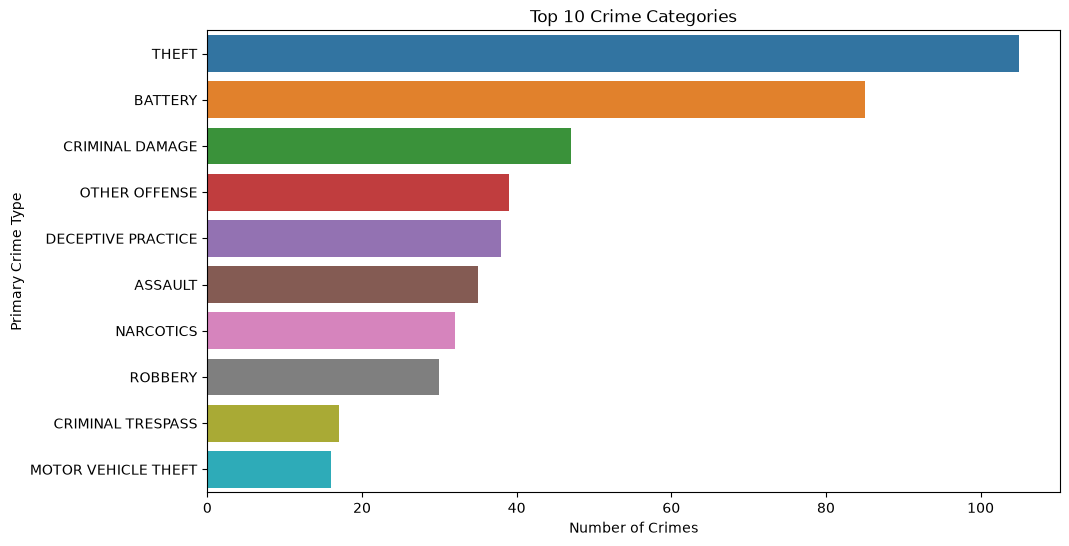

In [168]:
top_10_crimes = crime_category_summary.head(10)
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_10_crimes,
    x="crime_count",
    y="primary_type",
    hue="primary_type"
)

plt.title("Top 10 Crime Categories")
plt.xlabel("Number of Crimes")
plt.ylabel("Primary Crime Type")

plt.show()

In [169]:
#arrest rate
arrest_rate = crime_clean["arrest"].mean() * 100

print("Percentage of crimes resulting in arrest:",round(arrest_rate, 2),"%")

Percentage of crimes resulting in arrest: 25.0 %


In [ ]:
#only 25% of criminals got arrested but lets see year wise

In [185]:
year_arrest_outcomes = (crime_clean.groupby("Year")["arrest"].mean()*100).reset_index(name="percent")
year_arrest_outcomes["Year"].astype("str")
year_arrest_outcomes

,Year,percent
0,2012,100.000000
1,2013,100.000000
2,2014,0.000000
3,2015,50.000000
4,2016,24.385246


In [ ]:
# here we see that in 2014 no criminals were arrested and 2012 and 2013 all were arrested, and only 24.38 in 2016

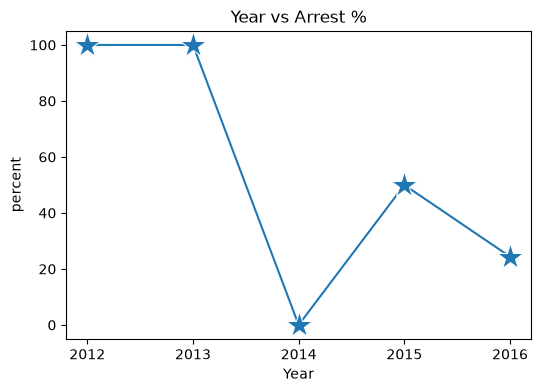

In [197]:
plt.figure(figsize=(6,4))
sns.lineplot(data=year_arrest_outcomes,x="Year",y="percent",marker="*",markersize=20)
plt.title("Year vs Arrest %")
plt.xticks(year_arrest_outcomes["Year"])
plt.show()

In [202]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

month_day_pivot = pd.crosstab(
    crime_clean["Month"],
    crime_clean["DayOfWeek"]
)

month_day_pivot

DayOfWeek,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
Month,,,,,,,
1,3,1,0,2,2,1,1
2,1,0,1,1,1,1,0
3,1,3,1,0,1,4,2
4,6,7,2,2,1,3,1
5,0,1,0,1,0,146,297
11,0,0,1,0,0,1,0


In [203]:
#but with no crimes is missing hence we will add months and fill them with zero

month_day_pivot = month_day_pivot.reindex(
    index=range(1, 13),
    columns=day_order,
    fill_value=0
)

display(month_day_pivot)

DayOfWeek,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
Month,,,,,,,
1,1,1,1,2,3,0,2
2,0,1,0,1,1,1,1
3,3,4,2,1,1,1,0
4,7,3,1,1,6,2,2
5,1,146,297,0,0,0,1
6,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0


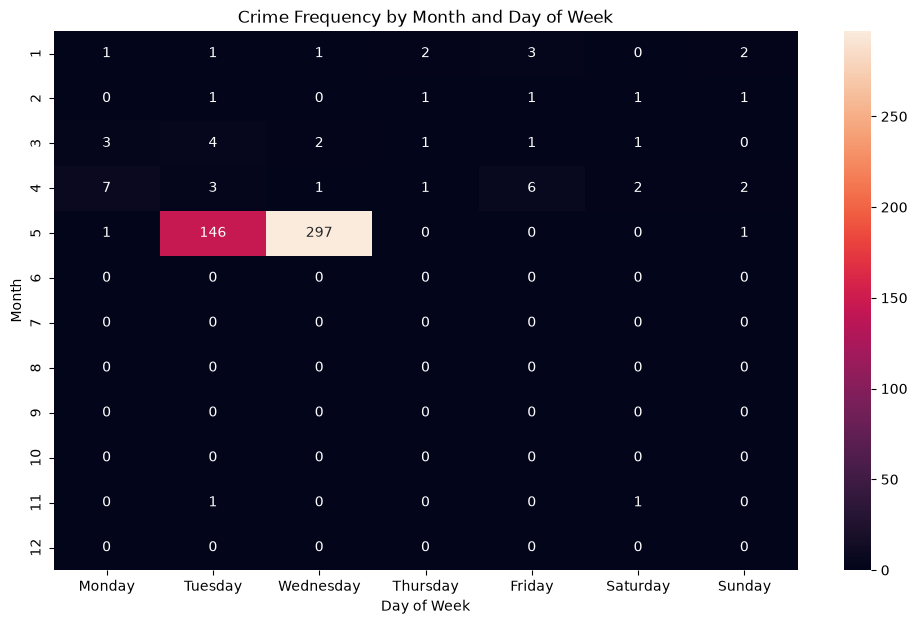

In [205]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    month_day_pivot,
    annot=True,
    fmt="d",
)

plt.title("Crime Frequency by Month and Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Month")
plt.show()

In [206]:
#Most crimes on Wednesday and 2nd most on Tuesday in the month of May (5) 

In [224]:
crime_by_month = (
    crime_clean
    .groupby(["Month"])
    .size()
)

crime_by_month = crime_by_month.reindex(range(0,13),fill_value=0).reset_index(name="crime_count")
crime_by_month

,Month,crime_count
0,0,0
1,1,10
2,2,5
3,3,12
4,4,22
5,5,445
6,6,0
7,7,0
8,8,0
9,9,0


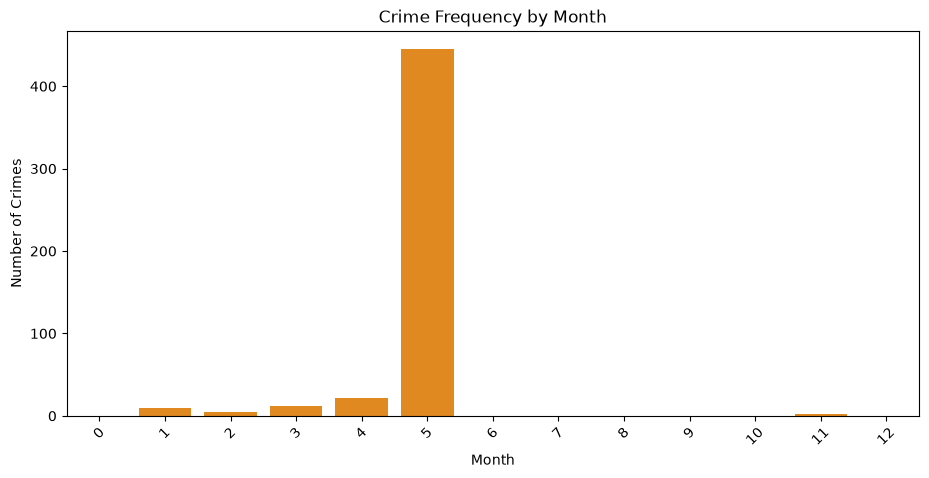

In [225]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=crime_by_month,
    x="Month",
    y="crime_count",
    color="darkorange"
)

plt.title("Crime Frequency by Month")
plt.xlabel("Month")
plt.ylabel("Number of Crimes")
plt.xticks(rotation=45)

plt.show()

In [ ]:
#top 5 community areas

In [227]:
if "community_name" not in crime_clean.columns:
    crime_clean = crime_clean.merge(
        community_clean[
            ["community_code","community_name"]
        ],
        on="community_code",
        how="left",
        validate="many_to_one"
    )

In [230]:
crime_clean["community_name"].head()

0    North Lawndale
1          Woodlawn
2            Austin
3            Austin
4            Austin
Name: community_name, dtype: str

In [233]:
top_10_communities = (
    crime_clean
    .groupby(
        ["community_code", "community_name"]
    )
    .size()
    .reset_index(name="crime_count")
    .sort_values(
        "crime_count",
        ascending=False
    )
    .head(10)
)

display(top_10_communities)

,community_code,community_name,crime_count
21,25,Austin,34
6,8,Near North Side,20
19,23,Humboldt Park,20
26,30,South Lawndale,16
39,43,South Shore,16
28,32,Loop,15
65,71,Auburn Gresham,14
4,6,Lake View,14
45,49,Roseland,14
62,68,Englewood,14


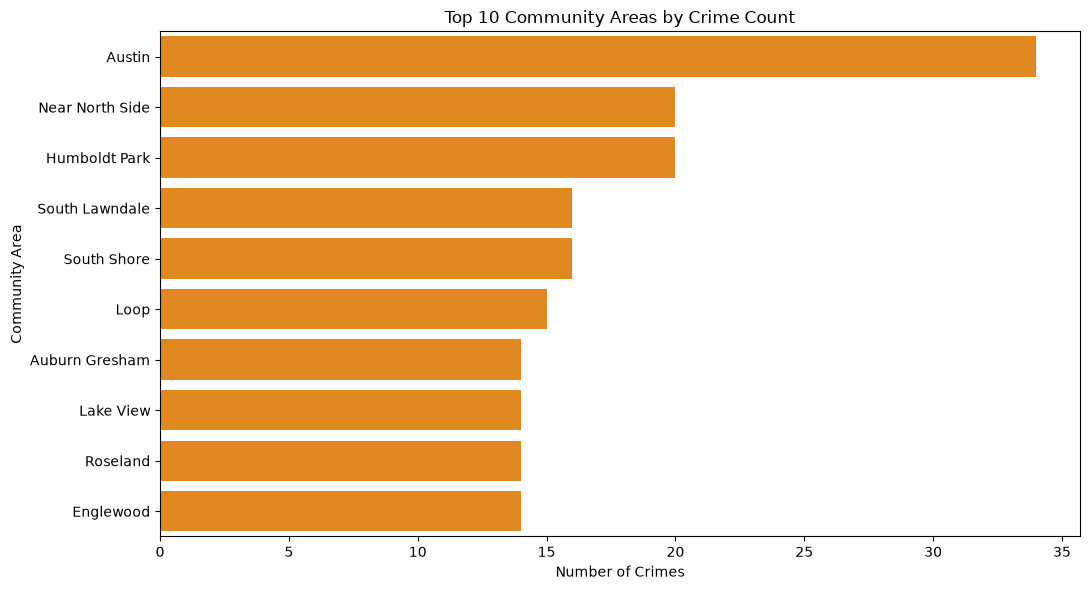

In [234]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_10_communities,
    x="crime_count",
    y="community_name",
    color="darkorange"
)

plt.title("Top 10 Community Areas by Crime Count")
plt.xlabel("Number of Crimes")
plt.ylabel("Community Area")

plt.tight_layout()
plt.show()

In [ ]:
# At Austin most number of crimes have occured 

# Use Case 3

## Note hourly computations are already done above Use Case 2, using synthetic data with seed(42)

In [245]:
analysis_df = crime_clean.copy()
analysis_df.columns

Index(['id', 'case_number', 'date', 'block', 'iucr_code', 'location_desc',
       'arrest', 'domestic', 'beat_num', 'district_code', 'ward_no',
       'community_code', 'fbi_code', 'x_coordinate', 'y_coordinate',
       'date_of_update', 'latitude', 'longitude', 'location', 'Year', 'Month',
       'DayOfWeek', 'missing_coordinate_flag', 'iucr', 'primary_type',
       'description', 'index code', 'synthetic_hour', 'synthetic_time_period',
       'community_name'],
      dtype='str')

In [246]:
analysis_df = analysis_df.merge(
    district_clean[
        [
            "district_code",
            "district_name"
        ]
    ],
    on="district_code",
    how="left",
    validate="many_to_one"
)

In [247]:
analysis_df.columns

Index(['id', 'case_number', 'date', 'block', 'iucr_code', 'location_desc',
       'arrest', 'domestic', 'beat_num', 'district_code', 'ward_no',
       'community_code', 'fbi_code', 'x_coordinate', 'y_coordinate',
       'date_of_update', 'latitude', 'longitude', 'location', 'Year', 'Month',
       'DayOfWeek', 'missing_coordinate_flag', 'iucr', 'primary_type',
       'description', 'index code', 'synthetic_hour', 'synthetic_time_period',
       'community_name', 'district_name'],
      dtype='str')

In [264]:
#analysis_df is master dataframe
community_crime_counts = (
    analysis_df
    .groupby(
        ["community_code", "community_name"]
    )
    .size()
    .reset_index(name="crime_count")
)

display(community_crime_counts)

,community_code,community_name,crime_count
0,1,Rogers Park,6
1,2,West Ridge,6
2,3,Uptown,5
3,4,Lincoln Square,2
4,6,Lake View,14
...,...,...,...
65,71,Auburn Gresham,14
66,73,Washington Heights,7
67,75,Morgan Park,3
68,76,O'Hare,2


In [265]:
mean_crimes_per_community = np.mean(
    community_crime_counts["crime_count"]
)

print(
    "Mean crimes per community area:",
    round(mean_crimes_per_community, 2)
)

Mean crimes per community area: 7.09


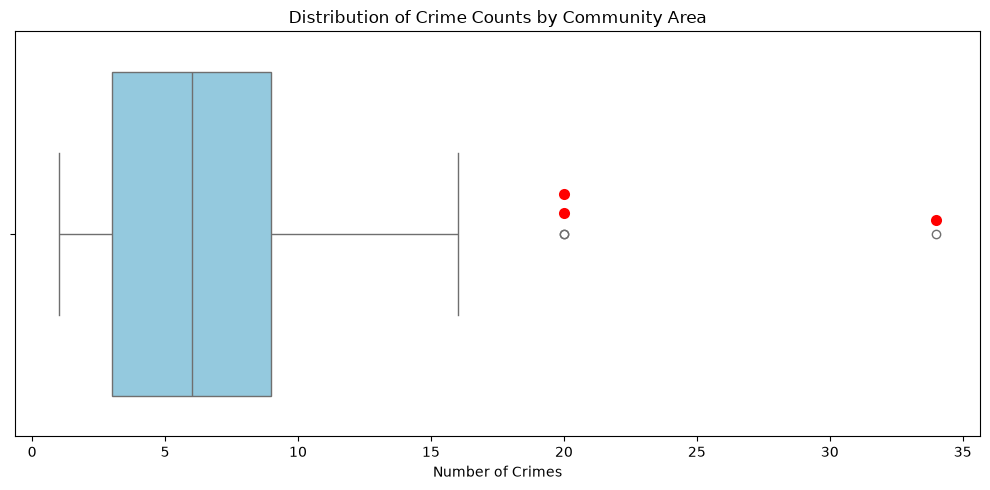

In [266]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=community_crime_counts,
    x="crime_count",
    color="skyblue"
)
sns.stripplot(
    data=high_crime_outliers,
    x="crime_count",
    color="red",
    size=8
)
plt.title("Distribution of Crime Counts by Community Area")
plt.xlabel("Number of Crimes")

plt.tight_layout()
plt.show()

In [267]:
q1 = np.percentile(
    community_crime_counts["crime_count"],
    25
)

q3 = np.percentile(
    community_crime_counts["crime_count"],
    75
)

iqr = q3 - q1

lower_limit = q1 - (1.5 * iqr)
upper_limit = q3 + (1.5 * iqr)

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 3.0
Q3: 9.0
IQR: 6.0
Lower limit: -6.0
Upper limit: 18.0


In [268]:
high_crime_outliers = (
    community_crime_counts[
        community_crime_counts["crime_count"]
        > upper_limit
    ]
    .sort_values(
        "crime_count",
        ascending=False
    )
    .reset_index(drop=True)
)

display(high_crime_outliers)

,community_code,community_name,crime_count
0,25,Austin,34
1,8,Near North Side,20
2,23,Humboldt Park,20


In [255]:
#well Austin, Near North Side and Humboldt Park became outliers as the data is unbalanced 

In [ ]:
#correlation df

In [271]:
correlation_df = analysis_df[
    [
        "Year",
        "Month",
        "arrest",
        "domestic",
        "synthetic_hour",
        "community_code",
        "district_code",
        "ward_no",
        "latitude",
        "longitude"
    ]
].copy()

In [272]:
correlation_df["arrest"] = (
    correlation_df["arrest"].astype(int)
)

correlation_df["domestic"] = (
    correlation_df["domestic"].astype(int)
)

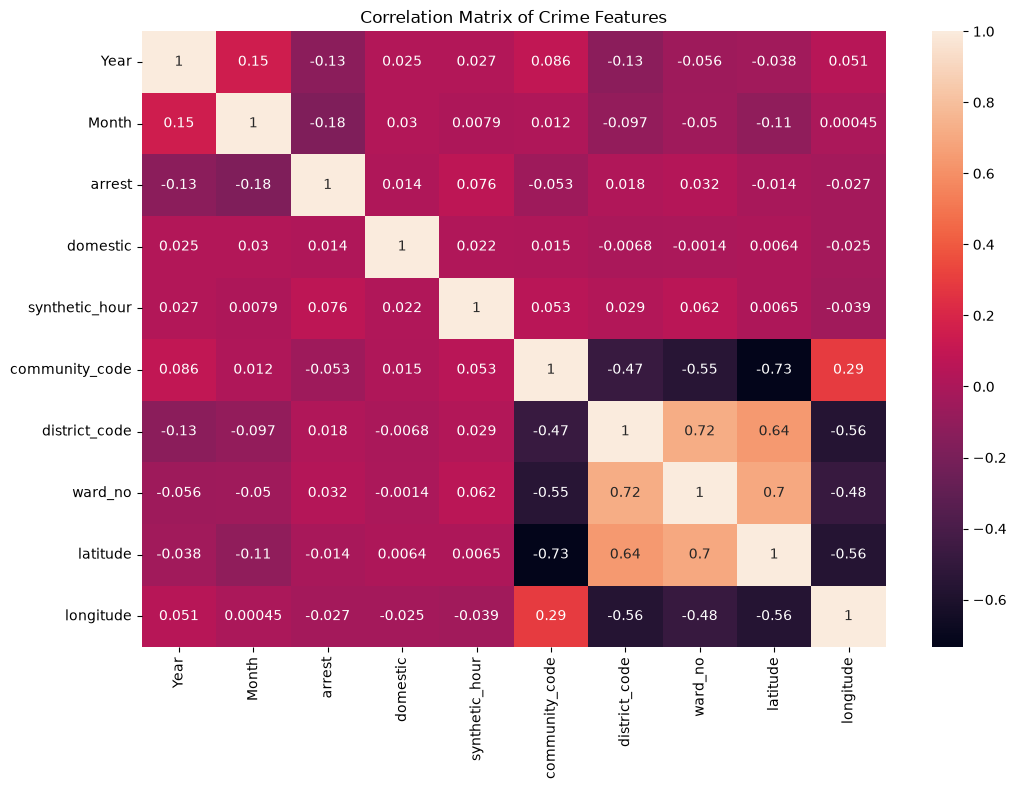

In [275]:
correlation_matrix = correlation_df.corr()
plt.figure(figsize=(12, 8))

sns.heatmap(
    data = correlation_matrix,
    annot=True,
)

plt.title("Correlation Matrix of Crime Features")
plt.show()

In [274]:
#this correalions shows a lot but we cant find causation based on it although some imp patters
#positively correlated :> distict_code and ward_no , ward_no and latitude 
#but latitude and community code are negatively correlated

# Use Case 4

In [276]:
import sqlite3

In [277]:
PROJECT_ROOT = Path.cwd().parent

DATABASE_PATH = (
    PROJECT_ROOT
    / "chicago_crime.db"
)

conn = sqlite3.connect(DATABASE_PATH)

print("Database created at:")
print(DATABASE_PATH)

Database created at:
C:\Users\ashirvad.s.singh\Desktop\Capstone\chicago_crime.db


In [ ]:
#only required fields for crime_db

In [278]:
crime_table_columns = [
    "id",
    "case_number",
    "date",
    "block",
    "iucr_code",
    "primary_type",
    "description",
    "location_desc",
    "arrest",
    "domestic",
    "beat_num",
    "district_code",
    "ward_no",
    "community_code",
    "fbi_code",
    "x_coordinate",
    "y_coordinate",
    "Year",
    "Month",
    "DayOfWeek",
    "date_of_update",
    "latitude",
    "longitude",
    "location"
]

In [280]:
crime_db_df = analysis_df[
    crime_table_columns
].copy()


In [281]:
crime_db_df.sample()

,id,case_number,date,block,iucr_code,primary_type,description,location_desc,arrest,domestic,...,fbi_code,x_coordinate,y_coordinate,Year,Month,DayOfWeek,date_of_update,latitude,longitude,location
242,10509608,HZ251109,2016-05-04,034XX N TRIPP AVE,610,BURGLARY,FORCIBLE ENTRY,RESIDENCE-GARAGE,False,False,...,5,1147446.0,1922503.0,2016,5,Wednesday,2016-05-11,41.94331,-87.733468,"(41.943309868, -87.733468027)"


In [282]:
crime_db_df.shape

(496, 24)

In [ ]:
#sql stores boolean in 1,0 so need to convert arrest & domestic column

In [283]:
crime_db_df["arrest"] = (
    crime_db_df["arrest"].astype(int)
)

crime_db_df["domestic"] = (
    crime_db_df["domestic"].astype(int)
)

In [285]:
#converting dates into ISO format YYYY-MM-DD

In [286]:
crime_db_df["date"] = (
    crime_db_df["date"]
    .dt.strftime("%Y-%m-%d")
)

crime_db_df["date_of_update"] = (
    crime_db_df["date_of_update"]
    .dt.strftime("%Y-%m-%d")
)

In [ ]:
#load all dataframes to SQlite

In [291]:
crime_db_df.to_sql(
    "crime",
    conn,
    if_exists="replace",
    index=False
)

496

In [292]:
community_clean.to_sql(
    "community",
    conn,
    if_exists="replace",
    index=False
)

77

In [293]:
district_clean.to_sql(
    "district",
    conn,
    if_exists="replace",
    index=False
)

22

In [294]:
beat_clean.to_sql(
    "police_beat",
    conn,
    if_exists="replace",
    index=False
)

275

In [295]:
iucr_clean.to_sql(
    "iucr",
    conn,
    if_exists="replace",
    index=False
)

410

In [298]:
ward_clean.to_sql(
    "ward_office",
    conn,
    if_exists="replace",
    index=False
)

58

In [299]:
conn.commit()

print("All tables loaded successfully.")

All tables loaded successfully.


In [301]:
tables_query = """
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name;
"""

database_tables = pd.read_sql(
    tables_query,
    conn
)

database_tables

,name
0,community
1,crime
2,district
3,iucr
4,police_beat
5,ward_office


In [302]:
conn.execute("SELECT COUNT(*) FROM crime").fetchall() #re-verified 

[(496,)]

## Task 2

In [ ]:
#query 1 : crime count per year

In [304]:
crime_yearly = pd.read_sql(
    """
    SELECT Year, COUNT(*) AS `No. of Crimes` FROM crime
    GROUP BY Year
    """,
    conn)

crime_yearly
    

,Year,No. of Crimes
0,2012,2
1,2013,1
2,2014,1
3,2015,4
4,2016,488


In [ ]:
#as we know in 2016 highest number of crimes

In [ ]:
#query 2: Top Five crime types and percentages

In [312]:
top_5_crimes_percentage = pd.read_sql(
    """
    SELECT 
        primary_type,
        COUNT(*) as `No. of Crimes`,
        ROUND(COUNT(*)*100/(SELECT COUNT(*) FROM crime),2) AS `Percentage`
    FROM crime
    GROUP BY primary_type
    ORDER BY COUNT(*) DESC
    LIMIT 5
    """,
    conn)

top_5_crimes_percentage
    
        

,primary_type,No. of Crimes,Percentage
0,THEFT,105,21.0
1,BATTERY,85,17.0
2,CRIMINAL DAMAGE,47,9.0
3,OTHER OFFENSE,39,7.0
4,DECEPTIVE PRACTICE,38,7.0


In [ ]:
#theft crime has most number of cases

In [ ]:
#Query 3: Arrest count per year

In [314]:
arrest_yearly = pd.read_sql(
    """
    SELECT 
        Year,
        COUNT(*) AS `Arrest Count`
    FROM crime
    WHERE arrest = 1
    GROUP BY Year
    """,
    conn)

arrest_yearly

,Year,Arrest Count
0,2012,2
1,2013,1
2,2015,2
3,2016,119


In [ ]:
#here 2014 has 1 row with arrest = 0 hence it didnt come in result, below is more robost code

In [318]:
arrest_yearly= pd.read_sql(
    """
    SELECT
        year,
        SUM(
            CASE
                WHEN arrest = 1 THEN 1
                ELSE 0
            END
        ) AS arrest_count
    FROM crime
    GROUP BY year
    ORDER BY year;
    """,
    conn
)

arrest_yearly

,Year,arrest_count
0,2012,2
1,2013,1
2,2014,0
3,2015,2
4,2016,119


## Task 3

In [ ]:
#create views

In [321]:
cursor = conn.cursor()

In [323]:

cursor.execute(
    """
    CREATE VIEW IF NOT EXISTS vw_crime_yearly  AS
    SELECT
        year,
        COUNT(*) AS crime_count,
        SUM(
            CASE
                WHEN arrest = 1 THEN 1
                ELSE 0
            END
        ) AS arrest_count,
        ROUND(
            SUM(
                CASE
                    WHEN arrest = 1 THEN 1.0
                    ELSE 0.0
                END
            ) * 100.0 / COUNT(*),
            2
        ) AS arrest_rate
    FROM crime
    GROUP BY year;
    """
)

In [324]:
cursor.execute(
    """
    DROP VIEW IF EXISTS vw_crime_by_category;
    """
)

cursor.execute(
    """
    CREATE VIEW vw_crime_by_category AS
    SELECT
        primary_type,
        COUNT(*) AS crime_count,
        ROUND(
            COUNT(*) * 100.0 /
            (SELECT COUNT(*) FROM crime),
            2
        ) AS percentage
    FROM crime
    WHERE primary_type IS NOT NULL
    GROUP BY primary_type;
    """
)

In [325]:
conn.commit()

print("Database views created successfully.")

Database views created successfully.


In [327]:
database_views = pd.read_sql(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'view'
    ORDER BY name;
    """,
    conn
)

database_views

,name
0,vw_crime_by_category
1,vw_crime_yearly


In [329]:
yearly_view_df = pd.read_sql(
    """
    SELECT *
    FROM vw_crime_yearly
    ORDER BY year;
    """,
    conn
)

yearly_view_df
#reading view into dfs 

,Year,crime_count,arrest_count,arrest_rate
0,2012,2,2,100.00
1,2013,1,1,100.00
2,2014,1,0,0.00
3,2015,4,2,50.00
4,2016,488,119,24.39


In [332]:
category_view_df = pd.read_sql(
    """
    SELECT *
    FROM vw_crime_by_category
    ORDER BY crime_count DESC;
    """,
    conn
)

category_view_df.head(1)

,primary_type,crime_count,percentage
0,THEFT,105,21.17


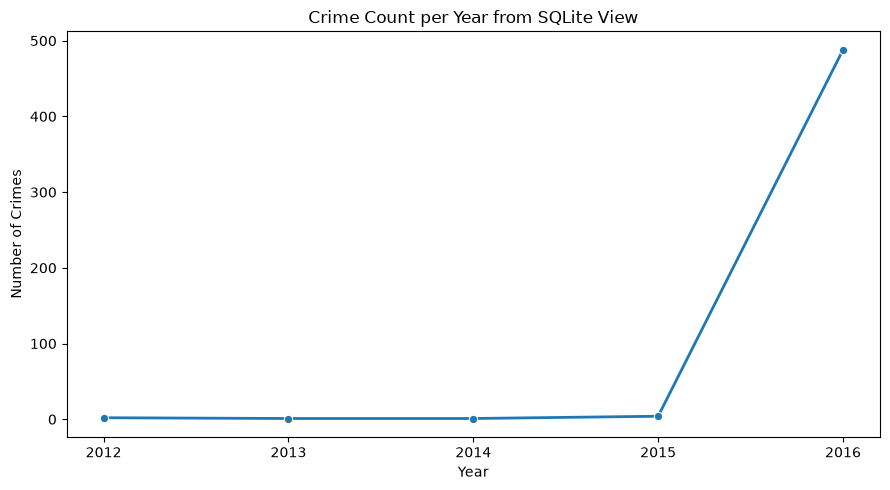

In [335]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=yearly_view_df,
    x="Year",
    y="crime_count",
    marker="o",
    linewidth=2
)

plt.title("Crime Count per Year from SQLite View")
plt.xlabel("Year")
plt.ylabel("Number of Crimes")
plt.xticks(yearly_view_df["Year"])

plt.tight_layout()
plt.show()

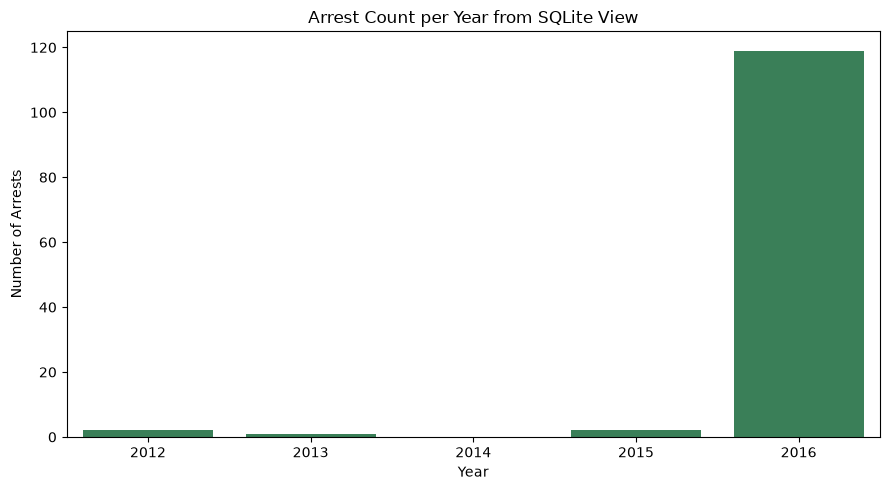

In [336]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=yearly_view_df,
    x="Year",
    y="arrest_count",
    color="seagreen"
)

plt.title("Arrest Count per Year from SQLite View")
plt.xlabel("Year")
plt.ylabel("Number of Arrests")

plt.tight_layout()
plt.show()

In [ ]:
## both the above plots prove that we can bring data from database and plot using pandas, also earlier we have plotted the same graph and results are matching hence proving consistency

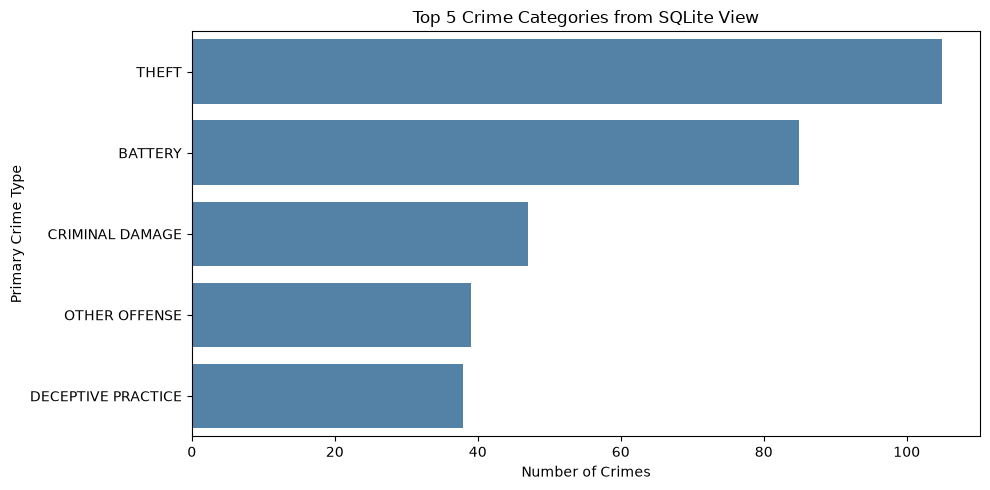

In [337]:
top_5_category_view = (
    category_view_df.head(5)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_5_category_view,
    x="crime_count",
    y="primary_type",
    color="steelblue"
)

plt.title("Top 5 Crime Categories from SQLite View")
plt.xlabel("Number of Crimes")
plt.ylabel("Primary Crime Type")

plt.tight_layout()
plt.show()

In [338]:
#closing the db connection
cursor.close()
conn.close()

print("SQLite connection closed.")

SQLite connection closed.


In [ ]:
cleaned_dataframes = {
    "crime_clean": crime_clean,
    "analysis_df": analysis_df,
    "community_clean": community_clean,
    "district_clean": district_clean,
    "beat_clean": beat_clean,
    "ward_clean": ward_clean,
    "iucr_clean": iucr_clean
}

for name, df in cleaned_dataframes.items():
    print(name, ":", df.shape)